In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, recall_score, confusion_matrix
from sklearn.inspection import permutation_importance
sns.set_theme(style='darkgrid')

In [2]:
df = pd.read_csv('../datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df = df.drop(columns=['customerID'])
y = (df['Churn']=='Yes').astype(int)
X = df.drop(columns='Churn')
print(df.shape)
y.value_counts(normalize=True)

(7043, 20)


Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

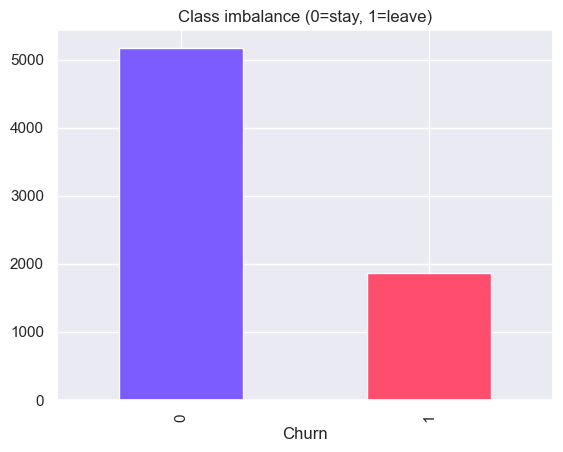

In [3]:
y.value_counts().plot(kind='bar', color=['#7c5cff','#ff4d6d'], title='Class imbalance (0=stay, 1=leave)')
plt.show()

In [4]:
num = X.select_dtypes(include='number').columns.tolist()
cat = X.select_dtypes(exclude='number').columns.tolist()
def prep():
    return ColumnTransformer([('n',StandardScaler(),num),('c',OneHotEncoder(handle_unknown='ignore'),cat)])
X_tr,X_te,y_tr,y_te = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [5]:
models = {
 'Logistic Regression': LogisticRegression(max_iter=1000),
 'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42)}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows=[]
for name,m in models.items():
    pipe = Pipeline([('p',prep()),('m',m)])
    acc = cross_val_score(pipe,X_tr,y_tr,cv=cv,scoring='accuracy').mean()
    rec = cross_val_score(pipe,X_tr,y_tr,cv=cv,scoring='recall').mean()
    auc = cross_val_score(pipe,X_tr,y_tr,cv=cv,scoring='roc_auc').mean()
    rows.append([name,acc,rec,auc])
table = pd.DataFrame(rows,columns=['Model','Accuracy','Recall (churn)','ROC-AUC']).round(3).sort_values('ROC-AUC',ascending=False)
table

,Model,Accuracy,Recall (churn),ROC-AUC
3,Gradient Boosting,0.803,0.529,0.848
0,Logistic Regression,0.802,0.543,0.846
1,Decision Tree,0.791,0.513,0.829
2,Random Forest,0.784,0.474,0.820


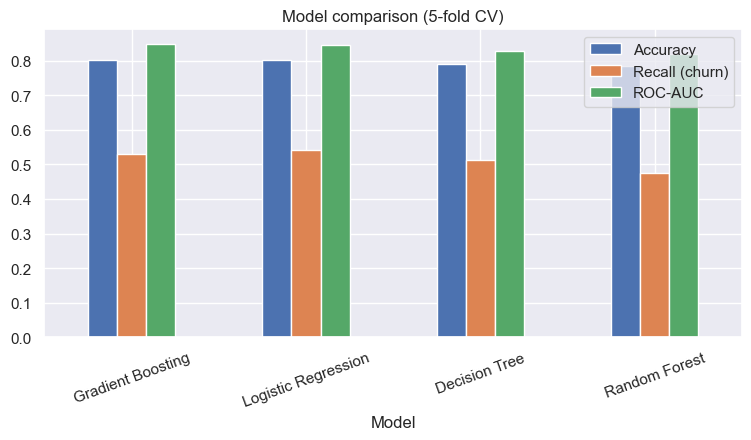

In [6]:
table.set_index('Model').plot(kind='bar', figsize=(9,4), title='Model comparison (5-fold CV)')
plt.xticks(rotation=20); plt.show()

In [7]:
base = Pipeline([('p',prep()),('m',RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))]).fit(X_tr,y_tr)
print('BEFORE class_weight')
print(classification_report(y_te,base.predict(X_te)))

BEFORE class_weight
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [8]:
bal = Pipeline([('p',prep()),('m',RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42,n_jobs=-1))]).fit(X_tr,y_tr)
print('AFTER class_weight=balanced')
print(classification_report(y_te,bal.predict(X_te)))
print('Recall before:',round(recall_score(y_te,base.predict(X_te)),3),'| after:',round(recall_score(y_te,bal.predict(X_te)),3))

AFTER class_weight=balanced
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1035
           1       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409

Recall before: 0.481 | after: 0.473


In [9]:
pipe = Pipeline([('p',prep()),('m',RandomForestClassifier(class_weight='balanced',random_state=42,n_jobs=-1))])
grid = {'m__n_estimators':[200,400],'m__max_depth':[6,10,None],'m__min_samples_leaf':[1,5,10]}
gs = GridSearchCV(pipe,grid,cv=cv,scoring='recall',n_jobs=-1).fit(X_tr,y_tr)
print(gs.best_params_, round(gs.best_score_,3))
best = gs.best_estimator_
print(classification_report(y_te,best.predict(X_te)))

{'m__max_depth': 6, 'm__min_samples_leaf': 5, 'm__n_estimators': 400} 0.799
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



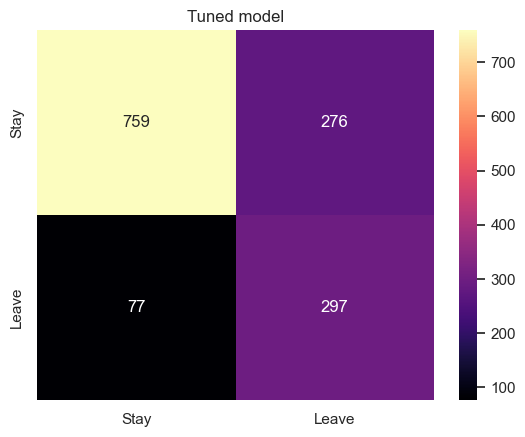

In [10]:
sns.heatmap(confusion_matrix(y_te,best.predict(X_te)),annot=True,fmt='d',cmap='magma',
            xticklabels=['Stay','Leave'],yticklabels=['Stay','Leave'])
plt.title('Tuned model'); plt.show()

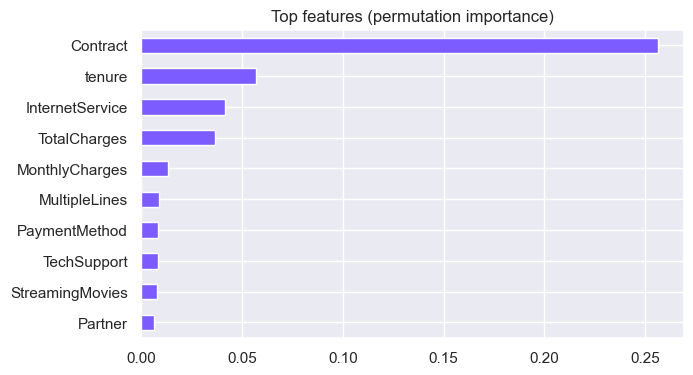

In [11]:
r = permutation_importance(best,X_te,y_te,scoring='recall',n_repeats=5,random_state=42,n_jobs=-1)
imp = pd.Series(r.importances_mean,index=X_te.columns).sort_values().tail(10)
imp.plot(kind='barh',color='#7c5cff',figsize=(7,4),title='Top features (permutation importance)')
plt.show()